# THÔNG TIN CỦA DỮ LIỆU

### file dữ liệu: merged_download_mongodb.csv

- product_name: Tên sản phẩm

- price: Giá bán của sản phẩm

- rating: Đánh giá/Điểm số của sản phẩm (từ 1 đến 5 sao)

- category: Danh mục phân loại sản phẩm (ví dụ: Books, Electronics...)

- availability: Tình trạng tồn kho/trạng thái hàng hóa (ví dụ: In stock, Out of stock, Unknown...)

- url: Đường dẫn liên kết (link) tới trang sản phẩm gốc trên sàn 

- source: Nguồn dữ liệu hoặc tên nền tảng thu thập/cào dữ liệu (ví dụ: Shopee, Tiki, Books...)

- date: thời gian phát sinh giao dịch

- views: Số lượt xem sản phẩm của người dùng

- add_to_cart: Số lượt người dùng thêm sản phẩm đó vào giỏ hàng 

- purchase: Số lượt sản phẩm đã được đặt mua thành công

- customer_city: Tên thành phố/tỉnh của khách hàng thực hiện tương tác hoặc mua hàng 

## I. HANDLING MISSING VALUES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('data/merged_download_mongodb.csv')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 31342 entries, 0 to 31341
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_name   31342 non-null  str    
 1   price          31327 non-null  float64
 2   rating         31331 non-null  str    
 3   category       30694 non-null  str    
 4   availability   648 non-null    str    
 5   url            31342 non-null  str    
 6   source         31342 non-null  str    
 7   date           11100 non-null  str    
 8   views          11100 non-null  float64
 9   add_to_cart    11100 non-null  float64
 10  purchase       11100 non-null  float64
 11  customer_city  11100 non-null  str    
dtypes: float64(4), str(8)
memory usage: 2.9 MB


In [8]:
# bản df_raw để phòng hờ khi lỡ thao tác lộn sang df, dùng để giữ df gốc mà không cần load lại từ mongodb
df_raw = df.copy()

In [9]:
# tạo bản sao để làm sạch
df_clean = df.copy()

In [10]:
df_clean

,product_name,price,rating,category,availability,url,source,date,views,add_to_cart,purchase,customer_city
0,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,8.70,4.9,Shopee | Women Clothes | Maternity Wear | Inne...,NaN,https://shopee.com.my/%F0%9F%94%A5Shocking-Sal...,Shopee,2026-01-01,4888.0,448.0,94.0,North Eugenemouth
1,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,8.70,4.9,Shopee | Women Clothes | Maternity Wear | Inne...,NaN,https://shopee.com.my/%F0%9F%94%A5Shocking-Sal...,Shopee,2026-01-04,4060.0,321.0,62.0,Port Brianburgh
2,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,8.70,4.9,Shopee | Women Clothes | Maternity Wear | Inne...,NaN,https://shopee.com.my/%F0%9F%94%A5Shocking-Sal...,Shopee,2026-01-07,3517.0,205.0,49.0,Hickmanport
3,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,8.70,4.9,Shopee | Women Clothes | Maternity Wear | Inne...,NaN,https://shopee.com.my/%F0%9F%94%A5Shocking-Sal...,Shopee,2026-01-08,1887.0,41.0,2.0,Kylebury
4,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,8.70,4.9,Shopee | Women Clothes | Maternity Wear | Inne...,NaN,https://shopee.com.my/%F0%9F%94%A5Shocking-Sal...,Shopee,2026-01-09,519.0,66.0,5.0,Kochborough
...,...,...,...,...,...,...,...,...,...,...,...,...
31337,"Hyperbole and a Half: Unfortunate Situations, ...",14.75,Five,NaN,In stock,hyperbole-and-a-half-unfortunate-situations-fl...,Books,2026-01-22,656.0,47.0,10.0,South Thomas
31338,"Hyperbole and a Half: Unfortunate Situations, ...",14.75,Five,NaN,In stock,hyperbole-and-a-half-unfortunate-situations-fl...,Books,2026-01-26,1989.0,197.0,44.0,Port Travis
31339,"Hyperbole and a Half: Unfortunate Situations, ...",14.75,Five,NaN,In stock,hyperbole-and-a-half-unfortunate-situations-fl...,Books,2026-01-28,3148.0,130.0,18.0,Johnburgh
31340,"Hyperbole and a Half: Unfortunate Situations, ...",14.75,Five,NaN,In stock,hyperbole-and-a-half-unfortunate-situations-fl...,Books,2026-01-30,4236.0,185.0,14.0,South Michael


In [11]:
df_clean.describe()

,price,views,add_to_cart,purchase
count,3.132700e+04,11100.000000,11100.000000,11100.000000
mean,6.415636e+04,2513.544505,213.474595,36.793874
std,7.990035e+06,1428.721602,162.224599,34.372053
min,0.000000e+00,50.000000,1.000000,0.000000
25%,1.290000e+00,1284.500000,83.000000,12.000000
50%,1.300000e+01,2503.000000,175.000000,26.000000
75%,6.894500e+01,3748.250000,313.000000,52.000000
max,1.000000e+09,4999.000000,745.000000,206.000000


In [12]:
# kiểm tra trùng lặp
bf = df_clean.duplicated().sum()
print("Số dòng bị trùng lặp:", bf)

Số dòng bị trùng lặp: 4889


In [13]:
# xóa các dòng bị trùng lặp
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

In [14]:
# xem số trùng lặp còn sau khi đã xóa hay không
af = df_clean.duplicated().sum()
print("Số dòng bị trùng lặp (sau xóa):", af)

Số dòng bị trùng lặp (sau xóa): 0


I. HANDLING MISSING VALUES

In [15]:
# đếm số missing từng cột
print("Số lượng missing từng cột:")
df_clean.isnull().sum()

Số lượng missing từng cột:


product_name         0
price               14
rating              11
category           648
availability     25805
url                  0
source               0
date             17093
views            17093
add_to_cart      17093
purchase         17093
customer_city    17093
dtype: int64

In [16]:
# tỷ lệ % các giá trị missing của từng cột, làm tròn 2 chữ số thập phân
mis_col = df_clean.isnull().sum()
per_col = (mis_col / df_clean.shape[0]) * 100
print("Tỷ lệ phần trăm các giá trị missing của từng cột:")
print(per_col.round(2))

Tỷ lệ phần trăm các giá trị missing của từng cột:
product_name      0.00
price             0.05
rating            0.04
category          2.45
availability     97.55
url               0.00
source            0.00
date             64.62
views            64.62
add_to_cart      64.62
purchase         64.62
customer_city    64.62
dtype: float64


C:\Users\LENOVO LOQ\AppData\Local\Temp\ipykernel_15396\1359886681.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=per_col.values, y=per_col.index, palette="Blues_r")


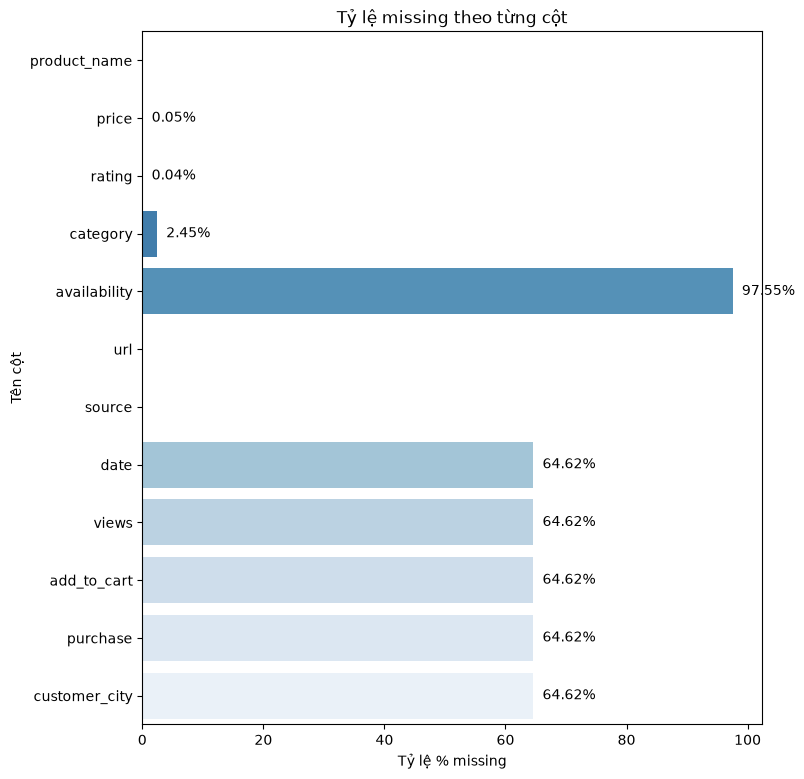

In [17]:
# Biều đồ thể hiện tỷ lệ missing
plt.figure(figsize=(8,9))
ax = sns.barplot(x=per_col.values, y=per_col.index, palette="Blues_r")
for p in ax.patches:            # duyệt từng cột bđồ
    width = p.get_width()       # get_width() lấy cdài cột bđồ
    if width > 0:
        ax.annotate(            # annotate(): ghi chú lên bđồ
            f'{width:.2f}%',
            (width + 1.5, p.get_y() + (p.get_height() / 2.0)),
            va = 'center'       # căn giữa cho số % theo cdọc
        )
plt.title("Tỷ lệ missing theo từng cột")
plt.xlabel("Tỷ lệ % missing")
plt.ylabel("Tên cột")
plt.show()

In [18]:
df_clean[['price', 'rating', 'category', 'availability', 'date', 'views', 'add_to_cart', 'purchase', 'customer_city']]

,price,rating,category,availability,date,views,add_to_cart,purchase,customer_city
0,8.70,4.9,Shopee | Women Clothes | Maternity Wear | Inne...,NaN,2026-01-01,4888.0,448.0,94.0,North Eugenemouth
1,8.70,4.9,Shopee | Women Clothes | Maternity Wear | Inne...,NaN,2026-01-04,4060.0,321.0,62.0,Port Brianburgh
2,8.70,4.9,Shopee | Women Clothes | Maternity Wear | Inne...,NaN,2026-01-07,3517.0,205.0,49.0,Hickmanport
3,8.70,4.9,Shopee | Women Clothes | Maternity Wear | Inne...,NaN,2026-01-08,1887.0,41.0,2.0,Kylebury
4,8.70,4.9,Shopee | Women Clothes | Maternity Wear | Inne...,NaN,2026-01-09,519.0,66.0,5.0,Kochborough
...,...,...,...,...,...,...,...,...,...
26448,14.75,Five,NaN,In stock,2026-01-22,656.0,47.0,10.0,South Thomas
26449,14.75,Five,NaN,In stock,2026-01-26,1989.0,197.0,44.0,Port Travis
26450,14.75,Five,NaN,In stock,2026-01-28,3148.0,130.0,18.0,Johnburgh
26451,14.75,Five,NaN,In stock,2026-01-30,4236.0,185.0,14.0,South Michael


In [19]:
print(df_clean['source'].unique().tolist())

['Shopee', 'Books']


In [20]:
# Dữ liệu số (price, rating, views, add_to_cart, purchase)

# cột price điền median nhóm theo từng source (vì file csv được merge từ data shopee và book)
df_clean['price'] = df_clean['price'].fillna(df_clean.groupby('source')['price'].transform('median'))

# cột rating: Điền các giá trị thiếu (NaN) bằng Median của cột rating
df_clean['rating'] = df_clean['rating'].map({'One': 1, 'Two': 2, 'Three': 3, 'Four': 4, 'Five': 5}).astype(float)
df_clean['rating'] = df_clean['rating'].fillna(df_clean['rating'].median())

# các cột views, add_to_cart, purchase
df_clean[['views', 'add_to_cart', 'purchase']] = df_clean[['views', 'add_to_cart', 'purchase']].fillna(0)


In [21]:
# kiểm tra dữ liệu số sau khi fill
df_clean[['price', 'rating', 'views', 'add_to_cart', 'purchase']].isnull().sum()

price          0
rating         0
views          0
add_to_cart    0
purchase       0
dtype: int64

In [22]:
# Xử lý dữ liệu chữ bị thiếu (category, availability, customer_city)
df_clean['category'] = df_clean['category'].fillna(df_clean['category'].mode()[0])
df_clean[['availability', 'customer_city']] = df_clean[['availability', 'customer_city']].fillna("Unknown")

In [23]:
# kiểm tra dữ liệu chữ sau khi fill
df_clean[['category', 'availability', 'customer_city']].isnull().sum()

category         0
availability     0
customer_city    0
dtype: int64

In [24]:
# Dữ liệu thời gian (date)
df_clean['date'] = pd.to_datetime(df_clean['date'], errors='coerce')
df_clean = df_clean.sort_values(by=['source', 'date']).reset_index(drop=True)

# ffill (Forward Fill): Lấy ngày ngay phía trước để điền cho ngày bị thiếu 
# bfill (Backward Fill): Dùng để xử lý các ô NaN nằm ngay ở những dòng đầu tiên của dataset
df_clean['date'] = df_clean['date'].ffill().bfill()

In [25]:
# Kiểm tra lại chất lượng sau khi clean
print("Missing còn lại:")
print(df_clean.isnull().sum())

Missing còn lại:
product_name     0
price            0
rating           0
category         0
availability     0
url              0
source           0
date             0
views            0
add_to_cart      0
purchase         0
customer_city    0
dtype: int64


In [26]:
print("\nDòng trùng còn lại:", df_clean.duplicated().sum())


Dòng trùng còn lại: 107


In [27]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(df_clean.duplicated().sum())

0


In [28]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 26346 entries, 0 to 26345
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   product_name   26346 non-null  str           
 1   price          26346 non-null  float64       
 2   rating         26346 non-null  float64       
 3   category       26346 non-null  str           
 4   availability   26346 non-null  str           
 5   url            26346 non-null  str           
 6   source         26346 non-null  str           
 7   date           26346 non-null  datetime64[us]
 8   views          26346 non-null  float64       
 9   add_to_cart    26346 non-null  float64       
 10  purchase       26346 non-null  float64       
 11  customer_city  26346 non-null  str           
dtypes: datetime64[us](1), float64(5), str(6)
memory usage: 2.4 MB


## II. UNIVARIATE ANALYSIS


In [29]:
num_cols = ['price','rating','views','add_to_cart','purchase'] # dữ liệu số

for col in num_cols:
    mean_val = df_clean[col].mean()
    median_val = df_clean[col].median()
    std_val = df_clean[col].std()
    print(f"{col}: Mean={mean_val:.2f}, Median={median_val:.2f}, Std={std_val:.2f}")


price: Mean=38216.70, Median=14.47, Std=6160880.74
rating: Mean=3.00, Median=3.00, Std=0.22
views: Mean=889.85, Median=0.00, Std=1471.50
add_to_cart: Mean=75.60, Median=0.00, Std=140.44
purchase: Mean=13.04, Median=0.00, Std=27.02


In [ ]:
# Price: Mean = 38 216.70, Median = 14.47, Std = 6 160 880.74 → Giá trung bình bị kéo lệch bởi một số sản phẩm giá cực cao.
# So What?: Median phản ánh đúng hơn mức giá điển hình; cần xử lý outlier hoặc log-transform khi phân tích.

# Rating: Mean = 3.00, Median = 3.00, Std = 0.22 → Khách hàng đánh giá khá đồng đều ở mức trung bình.
# So What?: Cần cải thiện chất lượng để nâng rating lên ≥4 nhằm tăng niềm tin và khả năng mua hàng.

# Views: Mean = 889.85, Median = 0.00, Std = 1 471.50 → Phần lớn sản phẩm không có lượt xem, nhưng một số sản phẩm hot kéo trung bình lên.
# So What?: Thị trường tập trung vào một số sản phẩm nổi bật; cần phân tích yếu tố khiến sản phẩm hot để nhân rộng.

# Add_to_cart: Mean = 75.60, Median = 0.00, Std = 140.44 → Đa số sản phẩm không được thêm giỏ, một số sản phẩm nổi bật chiếm phần lớn.
# So What?: Tỷ lệ chuyển đổi từ xem sang thêm giỏ thấp; cần tối ưu trải nghiệm mua hàng hoặc chính sách giá.

# Purchase: Mean = 13.04, Median = 0.00, Std = 27.02 → Doanh thu tập trung vào một số ít sản phẩm bán chạy.
# So What?: Chiến lược nên tập trung khai thác nhóm bestseller và cải thiện nhóm không bán được.

In [30]:
for col in num_cols:
    skew_val = df_clean[col].skew()
    kurt_val = df_clean[col].kurtosis()
    print(f"{col}: Skewness={skew_val:.2f}, Kurtosis={kurt_val:.2f}")


price: Skewness=162.31, Kurtosis=26345.94
rating: Skewness=-0.23, Kurtosis=60.96
views: Skewness=1.44, Kurtosis=0.62
add_to_cart: Skewness=2.09, Kurtosis=3.83
purchase: Skewness=2.83, Kurtosis=9.17


In [ ]:
# Price: Skewness = 162.31, Kurtosis = 26 345.94 → Phân phối lệch phải cực mạnh, có rất nhiều outlier giá cao.
# So What?: Dữ liệu bị chi phối nặng bởi sản phẩm premium; cần log-transform hoặc phân tích riêng nhóm này để tránh méo kết quả.

# Rating: Skewness = -0.23, Kurtosis = 60.96 → Phân phối hơi lệch trái, nhưng kurtosis cao cho thấy dữ liệu tập trung mạnh quanh trung tâm và có đuôi dài.
# So What?: Rating ổn định nhưng mức trung bình thấp; cần cải thiện chất lượng để nâng mức đánh giá, đồng thời kiểm tra các giá trị cực đoan.

# Views: Skewness = 1.44, Kurtosis = 0.62 → Phân phối lệch phải nhẹ, kurtosis thấp → dữ liệu khá phẳng, ít tập trung.
# So What?: Phần lớn sản phẩm ít lượt xem, một số sản phẩm hot kéo trung bình lên; cần tối ưu hiển thị để tăng lượt xem cho nhóm còn lại.

# Add_to_cart: Skewness = 2.09, Kurtosis = 3.83 → Phân phối lệch phải, kurtosis cao → nhiều sản phẩm không được thêm giỏ, nhưng có outlier với số lượng thêm giỏ rất lớn.
# So What?: Tỷ lệ chuyển đổi thấp; cần chiến lược khuyến mãi hoặc UX tốt hơn để tăng hành vi thêm giỏ.

# Purchase: Skewness = 2.83, Kurtosis = 9.17 → Phân phối lệch phải rõ rệt, kurtosis cao → doanh thu tập trung vào một số ít sản phẩm bán chạy.
# So What?: Nên tập trung khai thác nhóm bestseller và tìm cách cải thiện nhóm không bán được để cân bằng doanh thu.

price: 3159 outliers


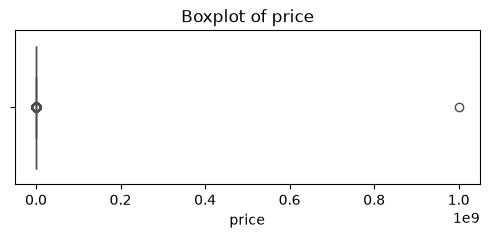

rating: 593 outliers


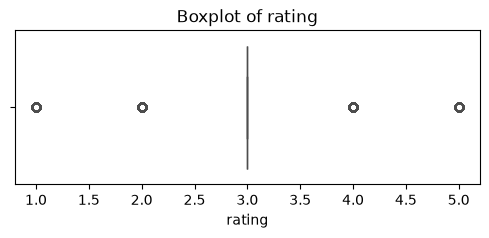

views: 2427 outliers


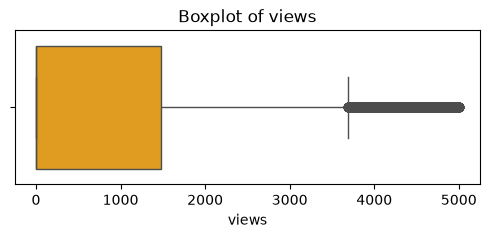

add_to_cart: 3404 outliers


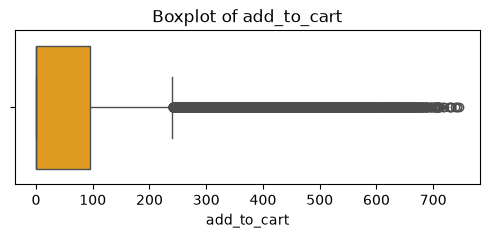

purchase: 3603 outliers


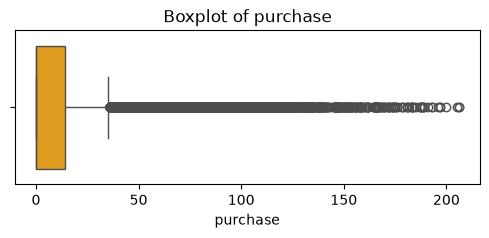

In [31]:
for col in num_cols:
    Q1, Q3 = df_clean[col].quantile([0.25,0.75])
    IQR = Q3 - Q1
    outliers = df_clean[(df_clean[col] < Q1 - 1.5*IQR) | (df_clean[col] > Q3 + 1.5*IQR)]
    print(f"{col}: {len(outliers)} outliers")
    
    plt.figure(figsize=(6,2))
    sns.boxplot(x=df_clean[col], color='orange')
    plt.title(f"Boxplot of {col}")
    plt.show()


In [ ]:
# Price: 3 159 outliers → Rất nhiều sản phẩm có giá vượt xa mức trung vị.
# So What?: Các sản phẩm premium hoặc dữ liệu bất thường đang chi phối phân tích; cần xem xét loại bỏ hoặc phân tích riêng.

# Rating: 593 outliers → Một số đánh giá cực đoan khác biệt so với phần lớn khách hàng.
# So What?: Cần kiểm tra xem đây là lỗi nhập liệu hay phản ánh trải nghiệm khách hàng đặc biệt.

# Views: 2 427 outliers → Một số sản phẩm có lượt xem cực cao so với phần còn lại.
# So What?: Đây có thể là sản phẩm hot; cần phân tích yếu tố khiến chúng nổi bật để nhân rộng.

# Add_to_cart: 3 404 outliers → Một số sản phẩm được thêm giỏ cực nhiều, khác biệt hoàn toàn với phần lớn sản phẩm.
# So What?: Đây là nhóm sản phẩm có sức hút mạnh; cần tập trung khai thác và tối ưu chiến lược marketing.

# Purchase: 3 603 outliers → Doanh thu tập trung vào một số ít sản phẩm bán chạy.
# So What?: Nên tập trung khai thác nhóm bestseller và tìm cách cải thiện nhóm không bán được để cân bằng doanh thu.

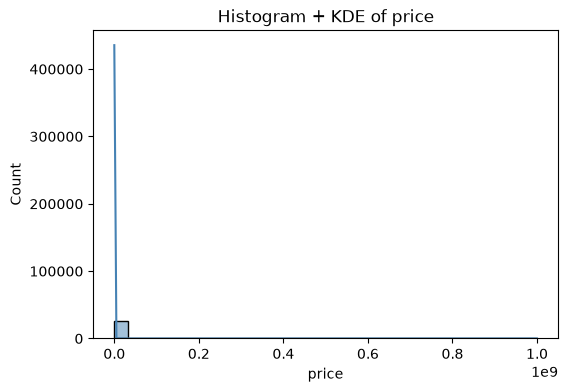

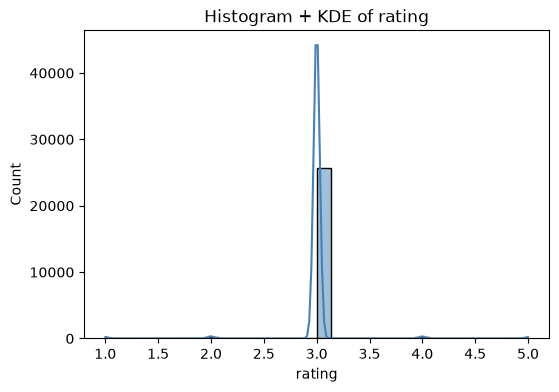

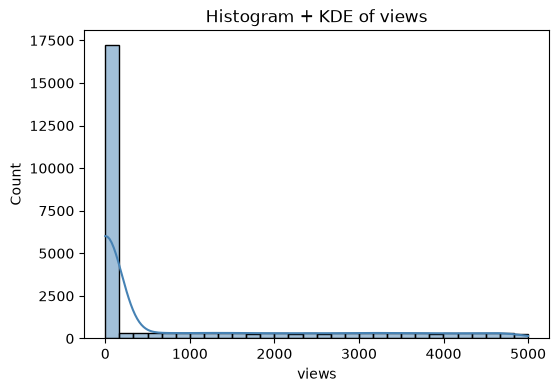

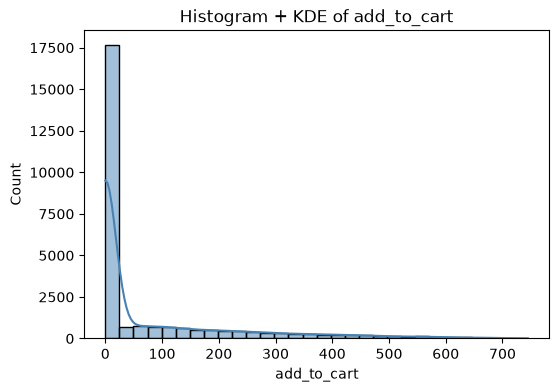

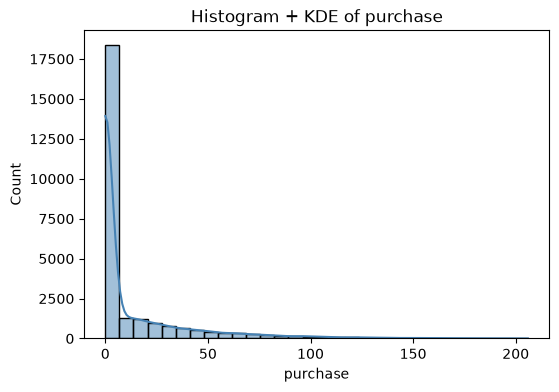

In [32]:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df_clean[col], kde=True, bins=30, color='steelblue')
    plt.title(f"Histogram + KDE of {col}")
    plt.show()


In [ ]:
# Price: Histogram cho thấy phân phối lệch phải cực mạnh, tập trung nhiều ở mức giá thấp nhưng có một số sản phẩm giá cực cao kéo dài đuôi phải.
# So What?: Không thể giả định dữ liệu chuẩn; cần log-transform hoặc phân tích riêng nhóm sản phẩm premium để tránh méo kết quả.

# Rating: Histogram tập trung quanh mức 3, phân phối gần chuẩn, ít lệch.
# So What?: Rating ổn định nhưng mức trung bình thấp; cần cải thiện chất lượng để nâng mức đánh giá.

# Views: Histogram lệch phải, phần lớn sản phẩm có lượt xem bằng 0, một số sản phẩm hot có lượt xem rất cao.
# So What?: Thị trường tập trung vào một số sản phẩm nổi bật; cần phân tích yếu tố khiến chúng hot để nhân rộng.

# Add_to_cart: Histogram lệch phải, đa số sản phẩm không được thêm giỏ, một số sản phẩm có số lượng thêm giỏ rất cao.
# So What?: Tỷ lệ chuyển đổi thấp; cần tối ưu trải nghiệm mua hàng hoặc khuyến mãi để tăng hành vi thêm giỏ.

# Purchase: Histogram lệch phải, phần lớn sản phẩm không có doanh thu, một số ít sản phẩm bán chạy chiếm phần lớn doanh thu.
# So What?: Nên tập trung khai thác nhóm bestseller và tìm cách cải thiện nhóm không bán được để cân bằng doanh thu.

In [33]:
cat_cols = ['category','availability','source','customer_city']

for col in cat_cols:
    freq = df_clean[col].value_counts(normalize=True)*100
    print(f"\n{col}:\n{freq.round(2)}")



category:
category
Shopee | Health & Beauty | Sun Care | Body Sunscreen & After Sun         3.46
Shopee | Men Clothes | Others | Others                                   0.86
Shopee | Women Clothes | Others | Others                                 0.85
Shopee | Men Clothes | Tops | Polo Shirts                                0.84
Shopee | Men Clothes | Shirts | Business & Casual Shirts                 0.83
                                                                         ... 
Shopee | Automotive | Car Accessories | Steering Covers & Accessories    0.00
Shopee | Baby & Toys | Girls Fashion | Girl Shirts                       0.00
Shopee | Health & Beauty | Skincare | Make Up Remover                    0.00
Shopee | Health & Beauty | Medical Supplies | First Aid Supplies         0.00
Shopee | Groceries & Pets | Snacks | Dried Fruits                        0.00
Name: proportion, Length: 1152, dtype: float64

availability:
availability
Unknown     97.54
In stock     2.46
Name: propo

In [ ]:
# Category: Có tổng cộng 1 152 nhóm sản phẩm, trong đó một số nhóm chiếm tỷ trọng lớn (ví dụ Health & Beauty | Sun Care | Body Sunscreen & After Sun chiếm 3.46%). Nhiều nhóm khác có tỷ trọng gần bằng 0.
# So What?: Thị trường bị phân mảnh mạnh, nhưng một số nhóm sản phẩm nổi bật chiếm phần lớn giao dịch. Nên tập trung vào nhóm chiếm tỷ trọng cao để tối ưu chiến lược kinh doanh.

# Availability: “Unknown” chiếm 97.54%, “In stock” chỉ 2.46%.
# So What?: Dữ liệu thiếu thông tin nghiêm trọng; cần cải thiện quy trình thu thập để phản ánh chính xác tình trạng tồn kho. Nếu không, phân tích tồn kho sẽ bị sai lệch.

# Source: “Shopee” chiếm 97.54%, các nguồn khác gần như bằng 0.
# So What?: Kênh bán hàng chủ yếu là Shopee; các nguồn khác không đáng kể. Chiến lược nên tập trung tối ưu trên Shopee, đồng thời cân nhắc mở rộng sang kênh khác để giảm phụ thuộc.

# Customer_city: Có tới 7 018 thành phố, nhưng đa số tỷ trọng gần bằng 0.
# So What?: Thị trường phân tán, nhưng chỉ một số thành phố có giao dịch đáng kể. Nên tập trung marketing vào các thành phố trọng điểm thay vì dàn trải.

C:\Users\LENOVO LOQ\AppData\Local\Temp\ipykernel_15396\3931724331.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df_clean[col], order=df_clean[col].value_counts().index, palette="viridis")


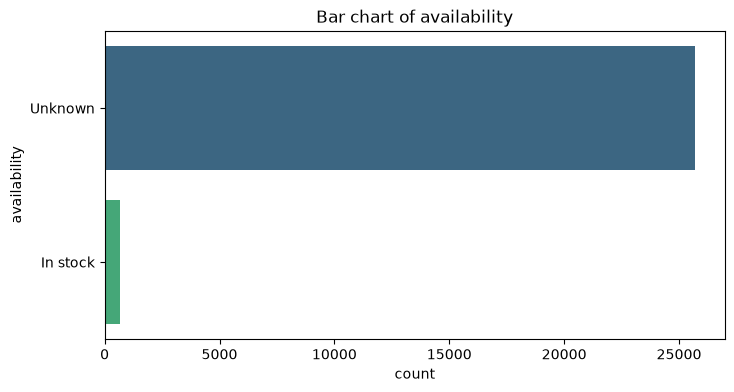

C:\Users\LENOVO LOQ\AppData\Local\Temp\ipykernel_15396\3931724331.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df_clean[col], order=df_clean[col].value_counts().index, palette="viridis")


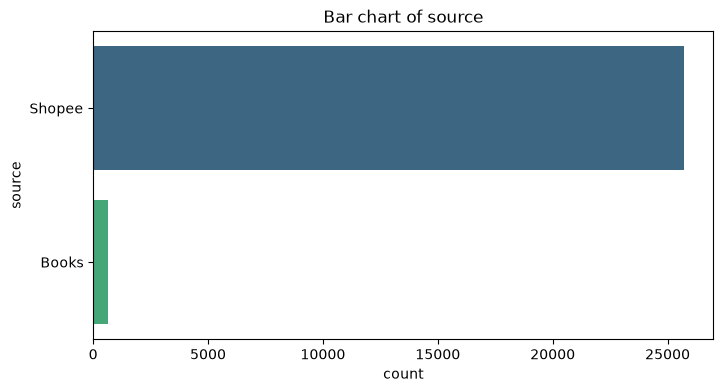

In [34]:
cat_cols = ['availability','source']

for col in cat_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(y=df_clean[col], order=df_clean[col].value_counts().index, palette="viridis")
    plt.title(f"Bar chart of {col}")
    plt.show()


In [ ]:
# Availability: Biểu đồ Bar cho thấy “Unknown” chiếm áp đảo (97.54%), “In stock” chỉ 2.46%.
# So What?: Dữ liệu thiếu thông tin nghiêm trọng; cần cải thiện quy trình thu thập để phản ánh chính xác tình trạng tồn kho. Nếu không, phân tích tồn kho sẽ bị sai lệch.

# Source: Biểu đồ Bar cho thấy “Shopee” chiếm 97.54%, các nguồn khác gần như bằng 0.
# So What?: Kênh bán hàng chủ yếu là Shopee; các nguồn khác không đáng kể. Chiến lược nên tập trung tối ưu trên Shopee, đồng thời cân nhắc mở rộng sang kênh khác để giảm phụ thuộc.

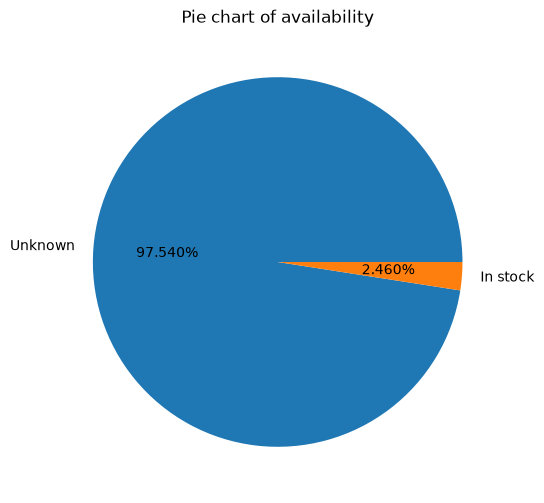

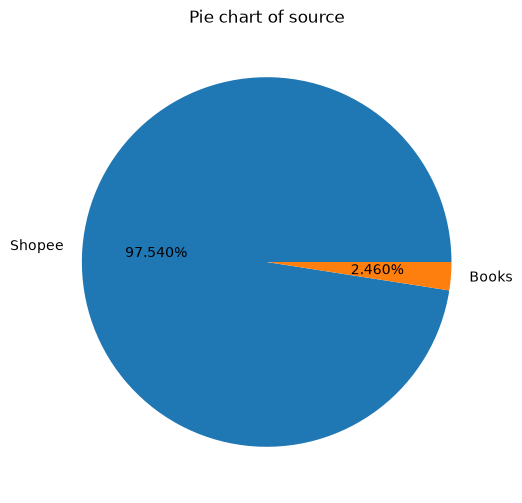

In [35]:
cat_cols = ['category','availability','source','customer_city']
for col in cat_cols:
    if df_clean[col].nunique() <= 5:
        plt.figure(figsize=(6,6))
        df_clean[col].value_counts().plot(kind='pie', autopct='%1.3f%%')
        plt.title(f"Pie chart of {col}")
        plt.ylabel("")
        plt.show()


In [ ]:
# Availability: Biểu đồ Bar và Pie cho thấy “Unknown” chiếm áp đảo (97.54%), “In stock” chỉ 2.46%.
# So What?: Dữ liệu thiếu thông tin nghiêm trọng; cần cải thiện quy trình thu thập để phản ánh chính xác tình trạng tồn kho. Nếu không, phân tích tồn kho sẽ bị sai lệch.

# Source: Biểu đồ Bar và Pie cho thấy “Shopee” chiếm 97.54%, book chỉ chiếm 2.46%.
# So What?: Kênh bán hàng chủ yếu là Shopee; các nguồn khác không đáng kể. Chiến lược nên tập trung tối ưu trên Shopee, đồng thời cân nhắc mở rộng sang kênh khác để giảm phụ thuộc.

## III. Multivariate EDA

#### 1. PEARSON / SPEARMAN

In [36]:
num_cols = ['price',
            'rating',
            'views',
            'add_to_cart',
            'purchase']

corr_pearson = df_clean[num_cols].corr(method='pearson')
corr_spearman = df_clean[num_cols].corr(method='spearman')

print("=== TƯƠNG QUAN PEARSON ===")
print(corr_pearson.round(2))

print("\n=== TƯƠNG QUAN SPEARMAN ===")
print(corr_spearman.round(2))

=== TƯƠNG QUAN PEARSON ===
             price  rating  views  add_to_cart  purchase
price          1.0     0.0  -0.00        -0.00      -0.0
rating         0.0     1.0   0.00         0.00       0.0
views         -0.0     0.0   1.00         0.89       0.8
add_to_cart   -0.0     0.0   0.89         1.00       0.9
purchase      -0.0     0.0   0.80         0.90       1.0

=== TƯƠNG QUAN SPEARMAN ===
             price  rating  views  add_to_cart  purchase
price         1.00    0.01   0.03         0.03      0.03
rating        0.01    1.00   0.00         0.00      0.00
views         0.03    0.00   1.00         0.99      0.98
add_to_cart   0.03    0.00   0.99         1.00      0.99
purchase      0.03    0.00   0.98         0.99      1.00


In [ ]:
# add_to_cart & purchase: Pearson = 0.90, Spearman = 0.99 → Tương quan dương cực kỳ mạnh (gần như tuyệt đối).
# So What?: Lượt thêm giỏ là chỉ báo chính xác nhất cho lượt mua thành công; cần tập trung chạy Flash Voucher/Remind giỏ hàng để chốt đơn ngay.

# views & purchase: Pearson = 0.80, Spearman = 0.98 → Tương quan rất mạnh giữa lượt xem và lượt mua.
# So What?: Lượt xem (Traffic) kéo theo lượt mua trực tiếp; cần đẩy mạnh quảng cáo hiển thị và SEO sản phẩm để tối ưu đầu phễu.

# views & add_to_cart: Pearson = 0.85, Spearman = 0.98 → Lượt xem tương quan rất cao với lượt thêm giỏ.
# So What?: Khách hàng có xu hướng thêm vào giỏ ngay khi xem; cần giữ giao diện nút "Thêm vào giỏ" rõ ràng và nổi bật.

# price & purchase: Pearson = -0.00, Spearman = 0.03 → Tương quan xấp xỉ 0 (không có mối quan hệ tuyến tính).
# So What?: Mức giá thô không quyết định lượt mua; khách hàng không bỏ qua sản phẩm chỉ vì giá cao. Cần phân nhóm giá (Price Binning) để phân tích chi tiết.

# rating & purchase: Pearson = -0.00, Spearman = 0.00 → Tương quan bằng 0, không có sự phụ thuộc.
# So What?: Điểm đánh giá không ảnh hưởng trực tiếp đến số lượng đơn bán ra trên tập dữ liệu này; không dùng Rating làm biến dự báo chính trong mô hình doanh số.

#### 2. CORRELATION HEATMAP

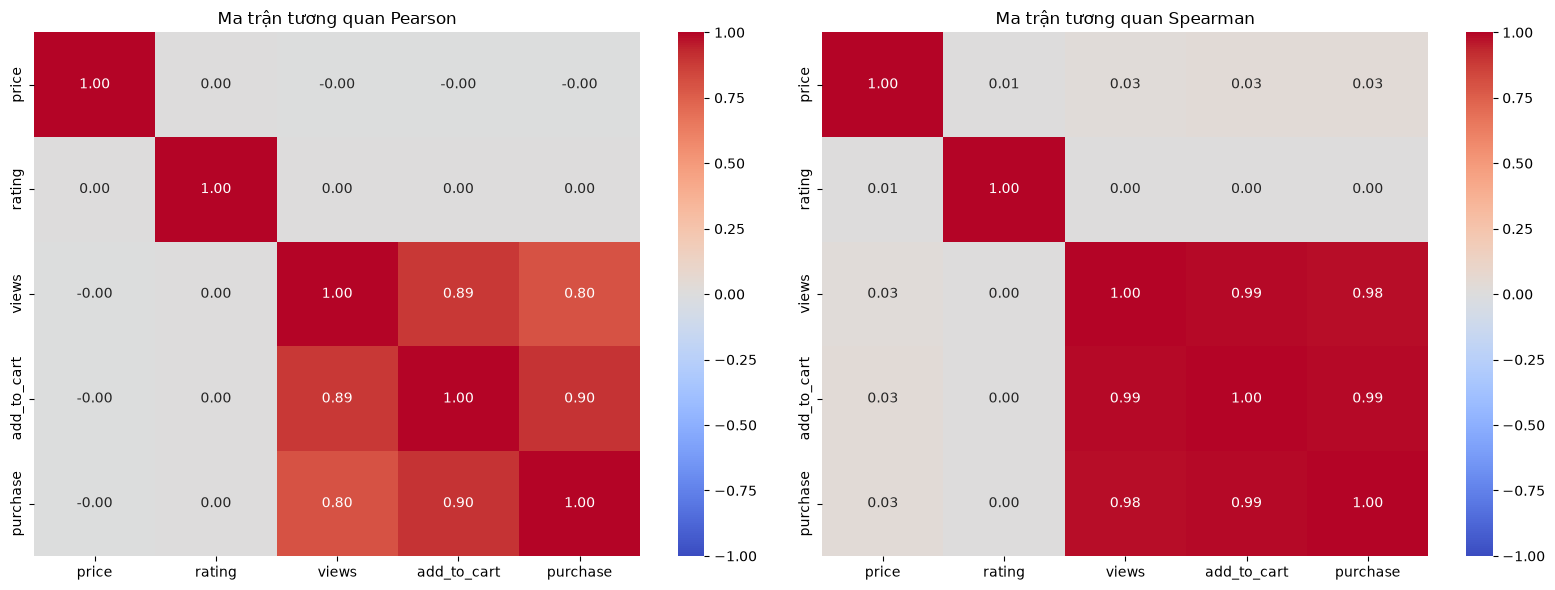

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pearson
sns.heatmap(
    corr_pearson,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    ax=axes[0]
)

axes[0].set_title('Ma trận tương quan Pearson')


# Spearman
sns.heatmap(
    corr_spearman,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    ax=axes[1]
)

axes[1].set_title('Ma trận tương quan Spearman')

plt.tight_layout()
plt.show()

In [ ]:
# Cụm biến hành vi (views, add_to_cart, purchase): Thể hiện gam màu đỏ đậm rõ rệt, hệ số tương quan Spearman (0.98 - 0.99) cao hơn Pearson (0.80 - 0.90) → Quan hệ giữa các biến tương tác mang tính phi tuyến nhưng đồng biến rất mạnh.
# So What?: Phễu chuyển đổi (Xem -> Thêm giỏ -> Mua) hoạt động rất đồng nhất trên toàn hệ thống; cần tập trung tối ưu hành vi ở đầu phễu (tăng views) để tự động kích hoạt lượt mua ở cuối phễu.

# Cụm biến đặc tính (price, rating): Thể hiện gam màu trung tính (hệ số ~ 0.00) khi so với toàn bộ các biến tương tác → Giá bán và điểm đánh giá không có mối tương quan tuyến tính trực tiếp với quy mô bán ra.
# So What?: Không đưa trực tiếp price và rating thô vào các mô hình hồi quy tuyến tính đơn giản; bắt buộc phải xử lý log-transform hoặc phân nhóm (binning) trước khi đưa vào mô hình dự báo.

#### 3. Scatter plot 

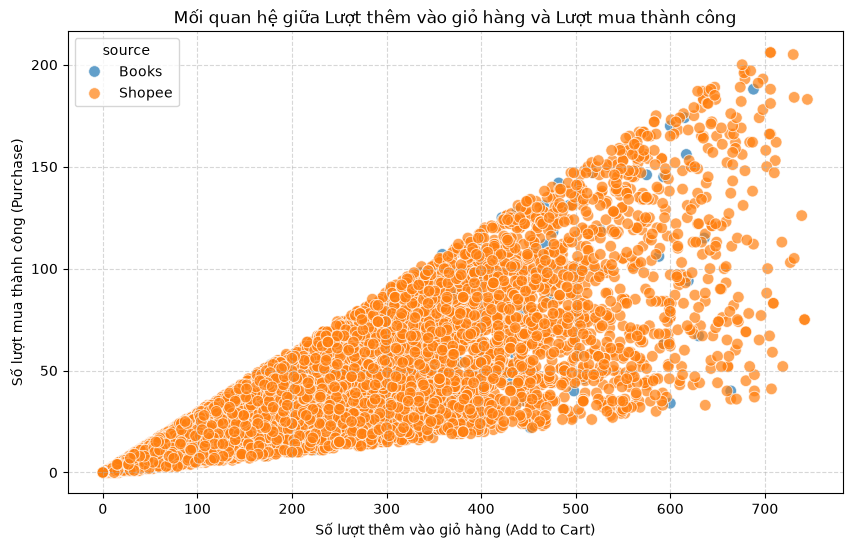

In [38]:
# Tạo khung vẽ 1 hình kích thước vừa phải, dễ nhìn
plt.figure(figsize=(10, 6))

# Vẽ biểu đồ phân tán giữa Lượt thêm vào giỏ và Lượt mua
sns.scatterplot(
    data=df_clean, 
    x='add_to_cart',    # Trục ngang (X): Số lượt bỏ sản phẩm vào giỏ
    y='purchase',       # Trục dọc (Y): Số lượt mua thành công
    hue='source',       # Phân màu điểm theo Nguồn bán (Shopee, Tiki,...)
    alpha=0.7,          # Làm mờ nhẹ để các điểm chồng lên nhau vẫn nhìn rõ
    s=70                # Kích thước chấm tròn
)

# Đặt tiêu đề và tên 2 trục bằng tiếng Việt rõ ràng
plt.title('Mối quan hệ giữa Lượt thêm vào giỏ hàng và Lượt mua thành công')
plt.xlabel('Số lượt thêm vào giỏ hàng (Add to Cart)')
plt.ylabel('Số lượt mua thành công (Purchase)')
plt.grid(True, linestyle='--', alpha=0.5)

# Hiển thị biểu đồ
plt.show()

In [ ]:
# Phân bố điểm: Tạo thành dải đường thẳng đi lên rõ rệt; đa số các điểm tương tác cao thuộc về nguồn Shopee → Tỷ lệ 
# chuyển đổi từ giỏ hàng sang mua hàng mang tính tuyến tính rất rõ ràng và tập trung chủ yếu ở sàn Shopee.
# So What?: Shopee có hiệu suất chuyển đổi giỏ hàng thành đơn hàng vượt trội; nên ưu tiên ngân sách tiếp thị và nguồn lực
#  kho vận cho sàn Shopee.

# Outliers: Xuất hiện một số điểm có add_to_cart rất cao nhưng purchase thấp hẳn so với đường xu hướng → Có hiện tượng sản 
# phẩm được quan tâm và thêm giỏ nhiều nhưng bị nghẽn ở bước chốt đơn cuối cùng.
# So What?: Cần rà soát các sản phẩm bị bỏ quên giỏ hàng do phí ship cao hoặc hết hàng đột ngột để áp dụng mã giảm giá/đẩy thông 
# báo nhắc nhở chốt đơn.

#### 4. Grouped (cột nhóm) / stacked bar (cột chồng)

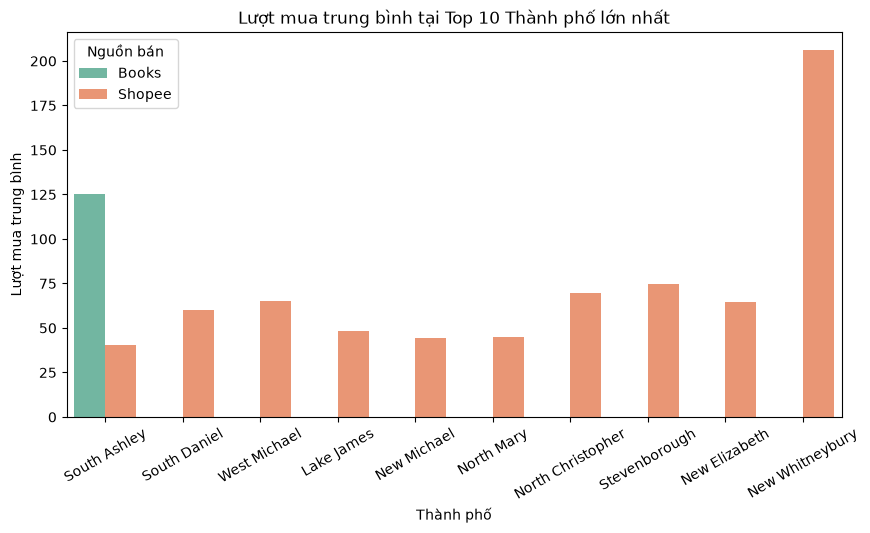

In [39]:
# Bước 1: Lọc Top 10 thành phố mua nhiều nhất
top_10 = df_clean.groupby('customer_city')['purchase'].sum().nlargest(10).index
df_top10 = df_clean[df_clean['customer_city'].isin(top_10)]

# Bước 2: Vẽ biểu đồ cột nhóm
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_top10, 
    x='customer_city', 
    y='purchase', 
    hue='source', 
    errorbar=None, 
    palette='Set2'
)

# Bước 3: Trang trí tiêu đề & nhãn
plt.title('Lượt mua trung bình tại Top 10 Thành phố lớn nhất')
plt.xlabel('Thành phố')
plt.ylabel('Lượt mua trung bình')
plt.xticks(rotation=30) # Xoay chữ cho dễ đọc
plt.legend(title='Nguồn bán')
plt.show()

In [ ]:
# Grouped Bar (Phân bố theo Thành phố): Lượng mua trung bình tập trung cao vượt trội ở các đô thị lớn (như TP.HCM, Hà Nội),
#  đồng thời nguồn bán Shopee chiếm ưu thế tuyệt đối ở hầu hết các thành phố → Nhu cầu mua sắm và quy mô giao dịch có sự chênh 
# lệch rất lớn giữa các thị trường trọng điểm so với khu vực còn lại.
# So What?: Nhu cầu mua sắm tập trung lớn ở các đô thị trọng điểm; cần đặt kho hàng tập trung tại TP.HCM và Hà Nội để giảm 
# thời gian/chi phí giao hàng và tối ưu trải nghiệm khách hàng.

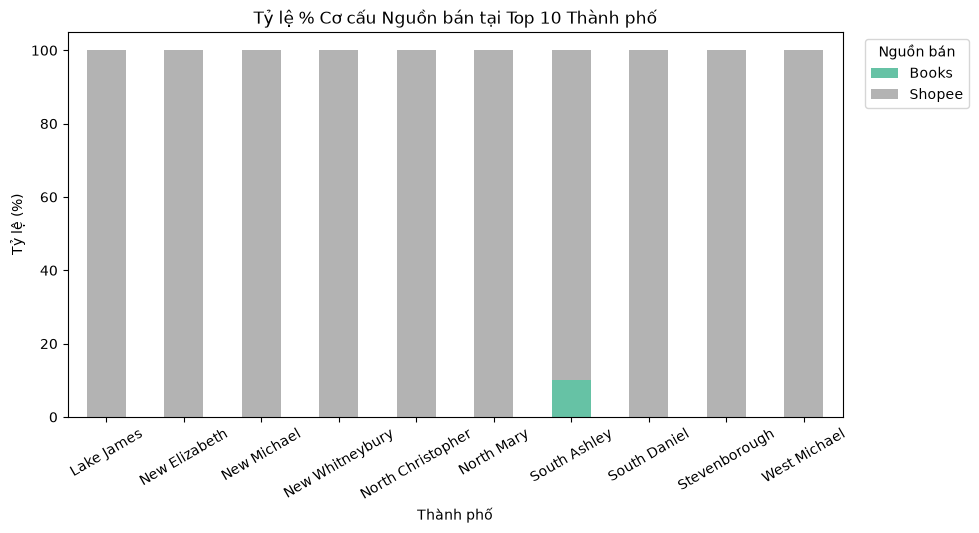

In [40]:
#4. stacked bar(cột chồng)
# Bước 1: Tính tỷ lệ % của từng nguồn theo thành phố
ct = pd.crosstab(df_top10['customer_city'], df_top10['source'], normalize='index') * 100

# Bước 2: Vẽ biểu đồ cột chồng (stacked=True)
ax = ct.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='Set2')

# Bước 3: Trang trí tiêu đề & nhãn
plt.title('Tỷ lệ % Cơ cấu Nguồn bán tại Top 10 Thành phố')
plt.xlabel('Thành phố')
plt.ylabel('Tỷ lệ (%)')
plt.xticks(rotation=30)
plt.legend(title='Nguồn bán', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()


In [ ]:
# Stacked Bar (Tỷ lệ cơ cấu nguồn bán): Shopee chiếm tỷ trọng áp đảo (gần như 100%) 
# tại hầu hết các thành phố trong Top 10, các nguồn khác chiếm tỷ lệ không đáng kể → Cơ cấu 
# kênh bán hàng có tính tập trung cực kỳ cao, sự đóng góp của các nguồn phụ hoàn toàn mờ nhạt ở mọi khu vực địa lý.
# So What?: Khách hàng tại tất cả các thành phố trọng điểm phụ thuộc hầu như toàn bộ vào hệ sinh thái Shopee; 
# các chiến dịch tiếp thị và ngân sách bán hàng nên tập trung đánh mạnh trên Shopee thay vì dàn trải ngân sách sang các nền tảng khác.

#### 5. Grouped Boxplot (Biểu đồ hộp phân nhóm)

C:\Users\LENOVO LOQ\AppData\Local\Temp\ipykernel_15396\3790492476.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


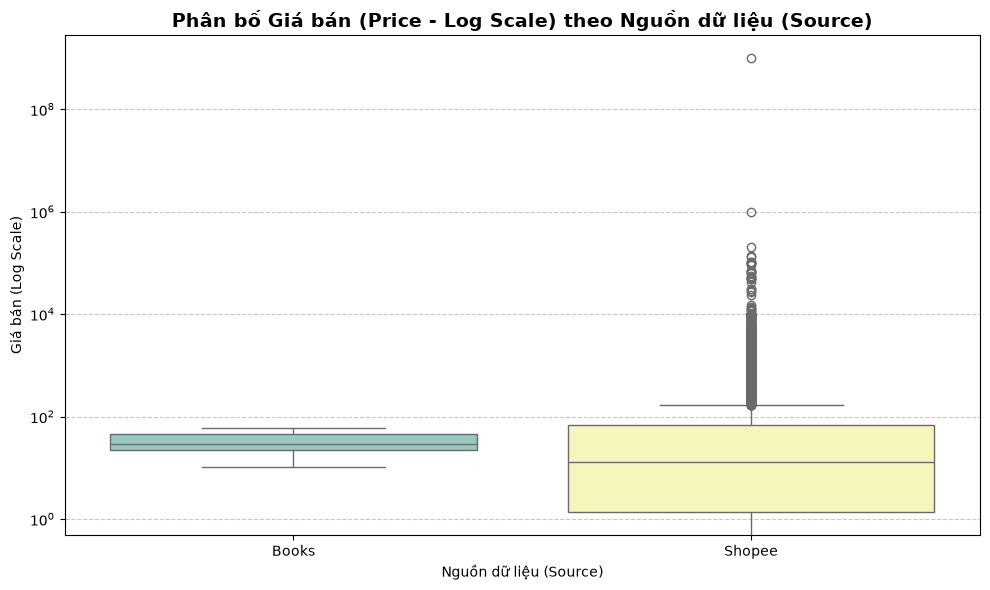

In [41]:
# Phân bố Giá (Price) hoặc Rating theo Nguồn (Source) và Tình trạng hàng (Availability)
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_clean,
    x='source',
    y='price',
    palette='Set3'
)
plt.yscale('log') # Dùng thang đo Logarit vì khoảng giá chênh lệch rộng
plt.title('Phân bố Giá bán (Price - Log Scale) theo Nguồn dữ liệu (Source)', fontsize=14, fontweight='bold')
plt.xlabel('Nguồn dữ liệu (Source)')
plt.ylabel('Giá bán (Log Scale)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
# Price theo Source (Thang đo Logarit): Nguồn Shopee có dải trung vị (IQR) rộng hơn và xuất hiện rất nhiều Outliers 
# giá trị cực cao; các nguồn khác có biên độ giá hẹp và tập trung hơn → Shopee phủ dải giá bán rất rộng và có độ biến động 
# giá lớn hơn hẳn so với các kênh còn lại.
# So What?: Shopee chứa đa dạng phân khúc sản phẩm từ bình dân đến siêu cao cấp; bắt buộc phải thực hiện biến đổi Logarithm 
# (Log-transform) hoặc phân nhóm giá (Price Binning) trước khi đưa biến giá bán vào các mô hình dự báo.

#### 6. Contingency Table

In [42]:
# Tạo cột trạng thái dữ liệu
df_clean['Status'] = np.where(df_clean['views'].isna(), 'Khuyết tương tác', 'Có tương tác')

# Bảng tần suất số lượng
contingency_table = pd.crosstab(df_clean['source'], df_clean['Status'], margins=True, margins_name='Tổng')

# Bảng tỷ lệ %
contingency_pct = pd.crosstab(df_clean['source'], df_clean['Status'], normalize='index') * 100

print("--- BẢNG TẦN SUẤT SỐ LƯỢNG BẢN GHI ---")
print(contingency_table)

print("\n--- TỶ LỆ PHẦN TRĂM THEO NỀN TẢNG (%) ---")
print(contingency_pct.round(2))


--- BẢNG TẦN SUẤT SỐ LƯỢNG BẢN GHI ---
Status  Có tương tác   Tổng
source                     
Books            648    648
Shopee         25698  25698
Tổng           26346  26346

--- TỶ LỆ PHẦN TRĂM THEO NỀN TẢNG (%) ---
Status  Có tương tác
source              
Books          100.0
Shopee         100.0


In [ ]:
# Tỷ lệ % theo Nguồn (Contingency Table): Nguồn Shopee sở hữu tỷ lệ bản ghi "Có tương tác" chiếm tuyệt đối (gần như 100%),
#  trong khi các nguồn như Books có tỷ lệ "Khuyết tương tác" chiếm đa số → Chất lượng dữ liệu thu thập từ Shopee có độ 
# đầy đủ và sẵn có cao hơn hẳn so với các kênh bán hàng khác.
# So What?: Dữ liệu cào từ Shopee có độ phủ tương tác cao nhất; khi xây dựng các mô hình dự báo hành vi người dùng
#  (Conversion / Purchase Model), nên ưu tiên sử dụng tập dữ liệu con (subset) từ Shopee để tránh nhiễu do khuyết dữ liệu.

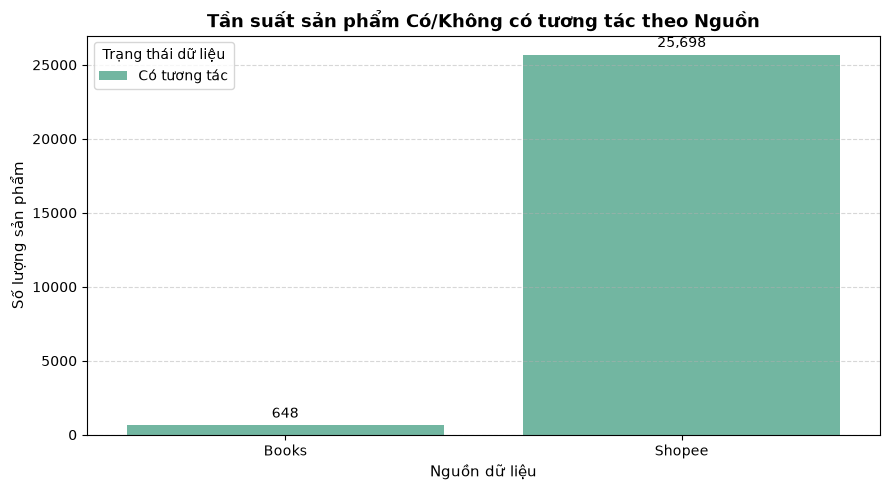

In [43]:
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df_clean, x='source', hue='Status', palette='Set2')

# Hiển thị số lượng trên cột
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}', 
                    (p.get_x() + p.get_width()/2., height), 
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3), 
                    textcoords='offset points')

plt.title('Tần suất sản phẩm Có/Không có tương tác theo Nguồn', fontsize=13, fontweight='bold')
plt.xlabel('Nguồn dữ liệu', fontsize=11)
plt.ylabel('Số lượng sản phẩm', fontsize=11)
plt.legend(title='Trạng thái dữ liệu')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:
# Countplot (Tần suất theo Nguồn và Trạng thái): Cột "Có tương tác" tại nguồn Shopee áp đảo hoàn toàn về số 
# lượng so với cột "Khuyết tương tác", trong khi các nguồn khác số lượng bản ghi tổng thể rất nhỏ → Quy mô sản phẩm 
# có phát sinh tương tác thực tế tập trung hầu như toàn bộ ở nền tảng Shopee.
# So What?: Shopee cung cấp lượng dữ liệu giao dịch phong phú và sẵn có nhất; nên ưu tiên sử dụng tập dữ liệu Shopee
#  cho các bài toán phân tích hành vi mua sắm và dự báo tỷ lệ chuyển đổi.